In [1]:
import h5pyd
import h5py
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
import haversine
from haversine import haversine, Unit
import numpy as np
from datetime import datetime
from matplotlib.patches import Rectangle

In [2]:
sites = pd.read_csv('C:/Users/sarah/Documents/GitHub/ORKA_StatusReport_FollowupPaper/StatusReport_FollowupPaper_Data/MasterSiteList_FollowupPaper.csv')
sites = sites.iloc[0:15,0:8]

In [3]:
%%time
#12 min
#Read in data, count up number of times steps and coords and then limit to 2013-2023 data
temp = pd.read_csv("D:/ORKA_StatusReportFollowupPaper/LO_SurfaceBrookingsAreas/processed_yearlyfiles/surface_temp_all.csv")
temp = temp.dropna()
#temp_east is 10,733,967 rows long
temp_east = pd.read_csv("D:/ORKA_StatusReportFollowupPaper/LO_SurfaceBrookingsAreas/processed_yearlyfiles/surface_temp_east_all.csv")
temp = pd.concat([temp,temp_east])
print("Number of time steps is", temp.ocean_time.nunique())
print("Lat/lon combos is", len(temp[['lon_rho','lat_rho']].drop_duplicates()))
temp.ocean_time = pd.to_datetime(temp.ocean_time)
temp = temp.loc[temp.ocean_time < "2023-12-31"].reset_index()

Number of time steps is 4383
Lat/lon combos is 48278
CPU times: total: 7min 31s
Wall time: 9min 12s


In [4]:
%%time
#Ok calculating the haversine distances over this many columns is not happening....

lat = sites.SiteLatitude[0]
lon = sites.SiteLongitude[0]
site = (lat, lon)
site_rounded = (round(lat,2), round(lon, 2))
#temp["lat_rounded"] = round(temp.lat_rho,2)
#temp["lon_rounded"] = round(temp.lon_rho,2)
temp_sub = temp.loc[(temp.lat_rho < site[0] +0.01) & (temp.lat_rho > site[0]-0.01)]
def hav_dist(row):
    site2 = (row["lat_rho"],row["lon_rho"])
    return haversine(site,site2)
dist = temp_sub.apply(hav_dist, axis = 1)
index1 = dist[dist == dist.min()].index
temp_forsites = temp.iloc[index1.values[:],]

for i in range(1,len(sites)): 
    #print(i, "has the latitude", sites.SiteLatitude[i])
    site = (sites.SiteLatitude[i], sites.SiteLongitude[i])
    temp_sub = temp.loc[(temp.lat_rho < site[0] +0.01) & (temp.lat_rho > site[0]-0.01)]
    dist = temp_sub.apply(hav_dist, axis = 1)
    index1 = dist[dist == dist.min()].index
    closest = temp.iloc[index1.values[:],]
    print(i)
    print(closest.iloc[1,6])
    temp_forsites = pd.concat([temp_forsites,closest])
    print(i," is finished, hooray!")

1
45.21331748549788
1  is finished, hooray!
2
44.78383099999047
2  is finished, hooray!
3
44.74972204231666
3  is finished, hooray!
4
43.342748340363855
4  is finished, hooray!
5
43.32052277193761
5  is finished, hooray!
6
43.29821697682596
6  is finished, hooray!
7
42.83479975382984
7  is finished, hooray!
8
42.78659473126096
8  is finished, hooray!
9
42.73804107337505
9  is finished, hooray!
10
42.70139552190807
10  is finished, hooray!
11
42.66455137467071
11  is finished, hooray!
12
42.43925529923458
12  is finished, hooray!
13
42.06055447045627
13  is finished, hooray!
14
42.03370062156226
14  is finished, hooray!
CPU times: total: 7min 55s
Wall time: 7min 47s


In [5]:
sites

,Site,SiteCode,Area,AreaCode,Port,SiteLatitude,SiteLongitude,Number2023Trans_Estiamted
0,Cape Lookout,LOOK,Cape Lookout,LKOUT,Pacific City,45.336730,-123.980000,0
1,Pacific City,PACC,Cape Lookout,LKOUT,Pacific City,45.212470,-123.985186,12
2,Cape Foulweather,FOUL,Cape Foulweather,FOULW,Depoe Bay,44.784468,-124.074200,44
3,Otter Rock,OTRK,Cape Foulweather,FOULW,Depoe Bay,44.746630,-124.072591,52
4,Gregory Point,GREG,Cape Arago,ARAGO,Coos Bay,43.339313,-124.378642,10
5,Simpson Reef,SIMP,Cape Arago,ARAGO,Coos Bay,43.315740,-124.404422,16
6,Drake Point,DRAK,Cape Arago,ARAGO,Coos Bay,43.300839,-124.400720,14
7,Blanco Reef,BLCO,Cape Blanco,BLANC,Port Orford,42.831791,-124.581814,16
8,Orford Reef,ORRF,Cape Blanco,BLANC,Port Orford,42.788491,-124.595368,26
9,Port Orford Heads,ORFH,Cape Blanco,BLANC,Port Orford,42.735759,-124.507747,26


C:/Users/sarah/Documents/GitHub/ORKA_StatusReport_FollowupPaper/StatusReport_FollowupPaper_Figures/TempHistograms/LOOK_TempDist_Feb2026.jpg


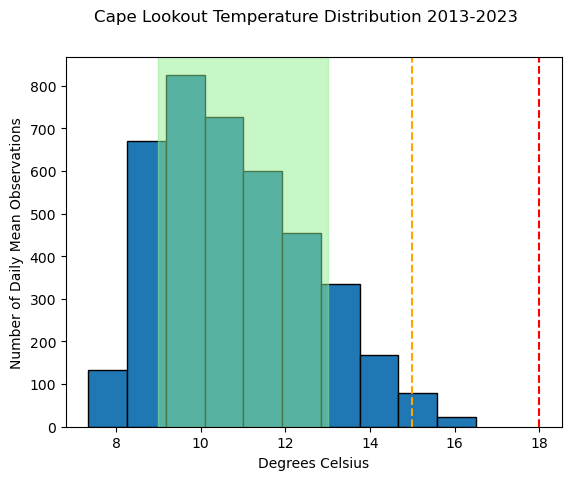

C:/Users/sarah/Documents/GitHub/ORKA_StatusReport_FollowupPaper/StatusReport_FollowupPaper_Figures/TempHistograms/PACC_TempDist_Feb2026.jpg


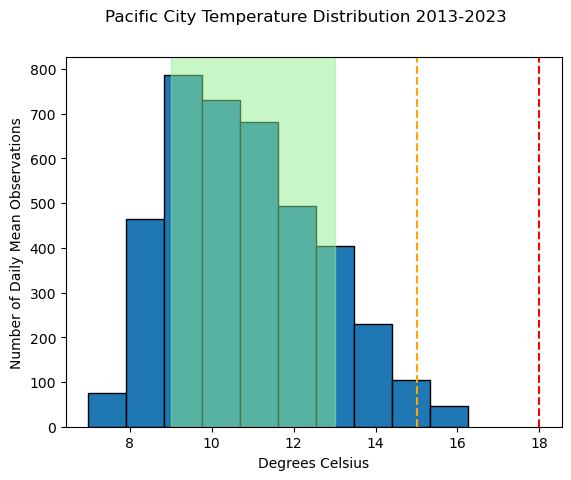

C:/Users/sarah/Documents/GitHub/ORKA_StatusReport_FollowupPaper/StatusReport_FollowupPaper_Figures/TempHistograms/FOUL_TempDist_Feb2026.jpg


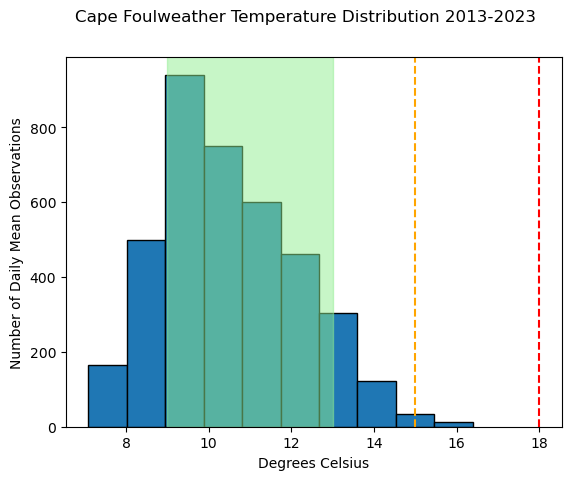

C:/Users/sarah/Documents/GitHub/ORKA_StatusReport_FollowupPaper/StatusReport_FollowupPaper_Figures/TempHistograms/OTRK_TempDist_Feb2026.jpg


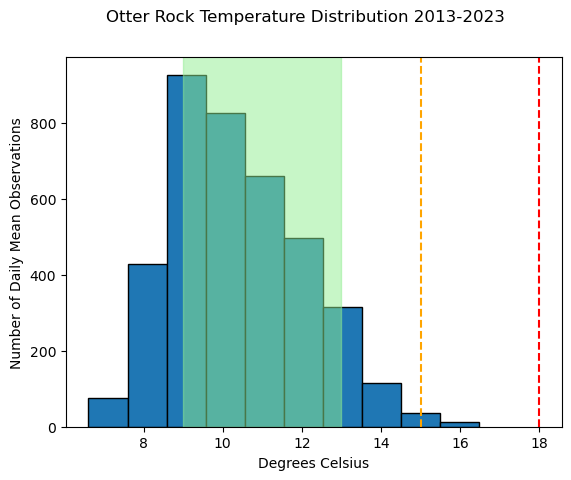

C:/Users/sarah/Documents/GitHub/ORKA_StatusReport_FollowupPaper/StatusReport_FollowupPaper_Figures/TempHistograms/GREG_TempDist_Feb2026.jpg


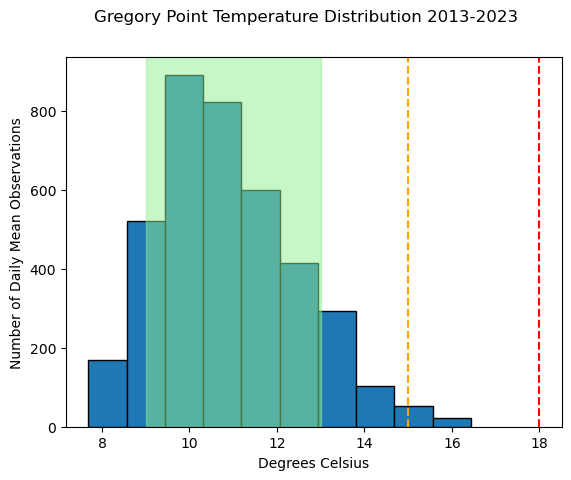

C:/Users/sarah/Documents/GitHub/ORKA_StatusReport_FollowupPaper/StatusReport_FollowupPaper_Figures/TempHistograms/SIMP_TempDist_Feb2026.jpg


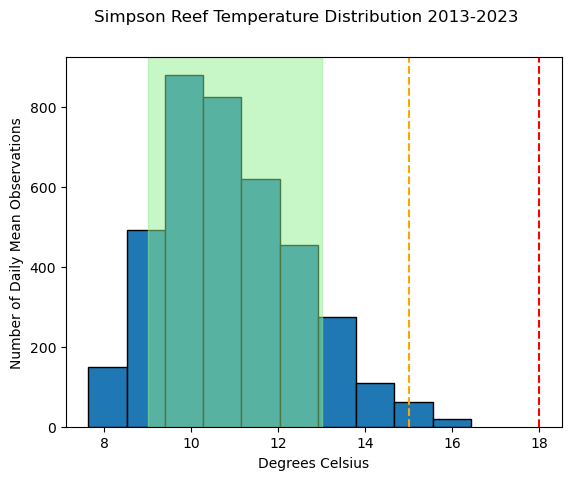

C:/Users/sarah/Documents/GitHub/ORKA_StatusReport_FollowupPaper/StatusReport_FollowupPaper_Figures/TempHistograms/DRAK_TempDist_Feb2026.jpg


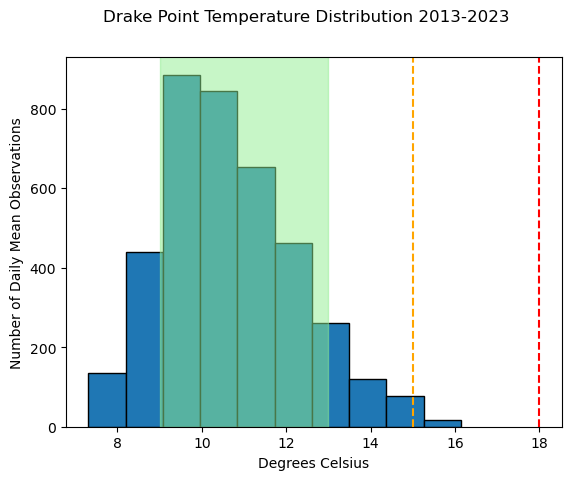

C:/Users/sarah/Documents/GitHub/ORKA_StatusReport_FollowupPaper/StatusReport_FollowupPaper_Figures/TempHistograms/BLCO_TempDist_Feb2026.jpg


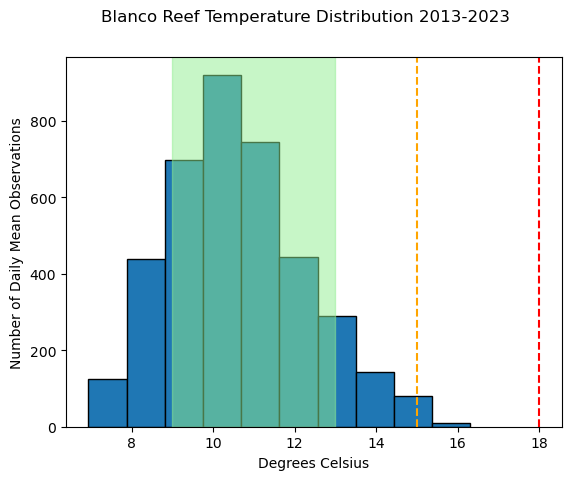

C:/Users/sarah/Documents/GitHub/ORKA_StatusReport_FollowupPaper/StatusReport_FollowupPaper_Figures/TempHistograms/ORRF_TempDist_Feb2026.jpg


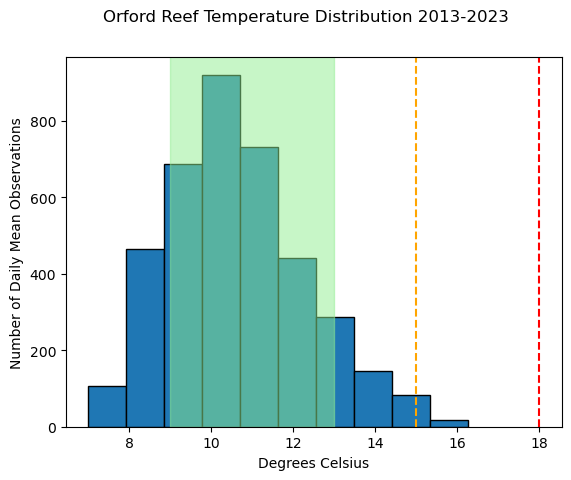

C:/Users/sarah/Documents/GitHub/ORKA_StatusReport_FollowupPaper/StatusReport_FollowupPaper_Figures/TempHistograms/ORFH_TempDist_Feb2026.jpg


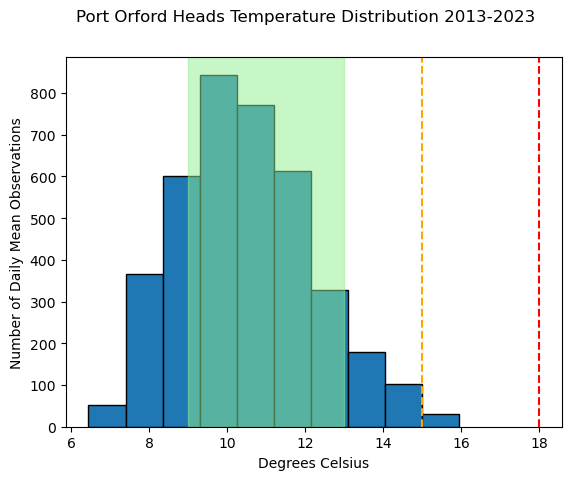

C:/Users/sarah/Documents/GitHub/ORKA_StatusReport_FollowupPaper/StatusReport_FollowupPaper_Figures/TempHistograms/RFSH_TempDist_Feb2026.jpg


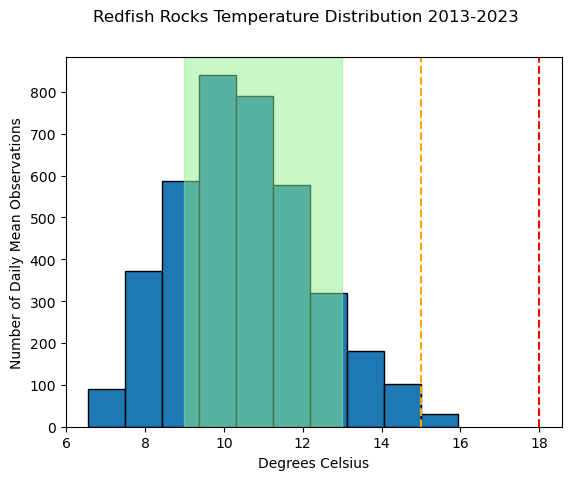

C:/Users/sarah/Documents/GitHub/ORKA_StatusReport_FollowupPaper/StatusReport_FollowupPaper_Figures/TempHistograms/HMBG_TempDist_Feb2026.jpg


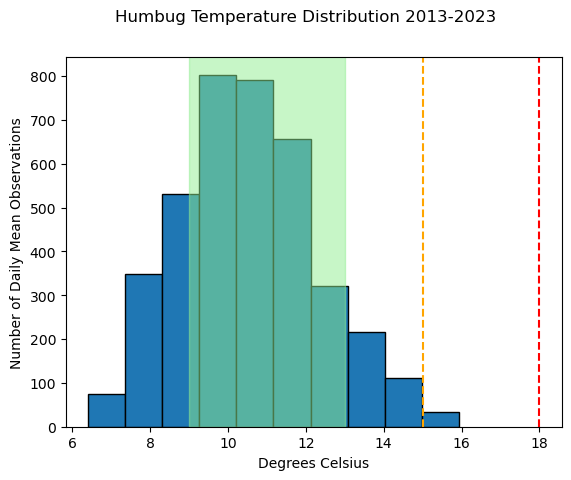

C:/Users/sarah/Documents/GitHub/ORKA_StatusReport_FollowupPaper/StatusReport_FollowupPaper_Figures/TempHistograms/ROGU_TempDist_Feb2026.jpg


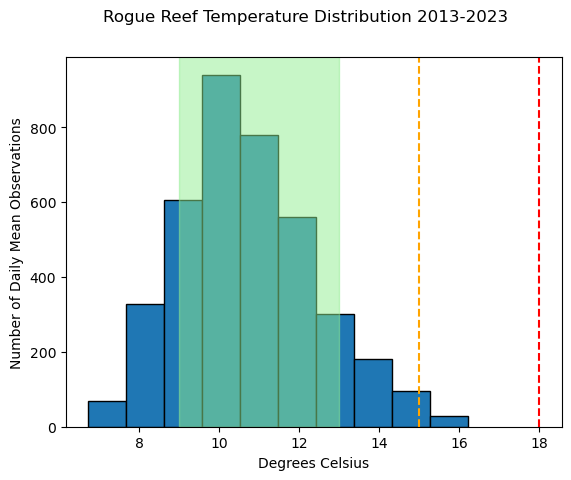

C:/Users/sarah/Documents/GitHub/ORKA_StatusReport_FollowupPaper/StatusReport_FollowupPaper_Figures/TempHistograms/HARB_TempDist_Feb2026.jpg


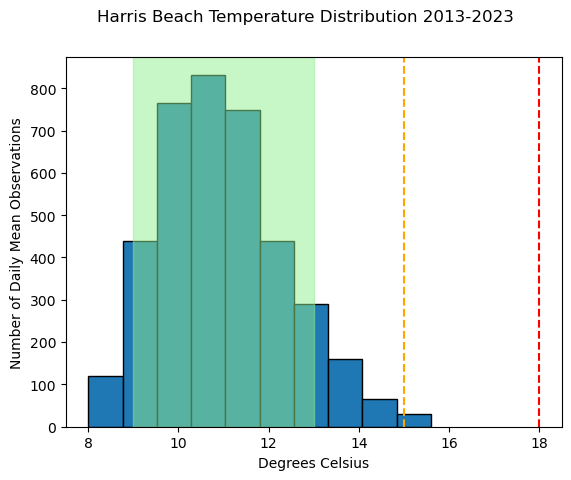

C:/Users/sarah/Documents/GitHub/ORKA_StatusReport_FollowupPaper/StatusReport_FollowupPaper_Figures/TempHistograms/CHET_TempDist_Feb2026.jpg


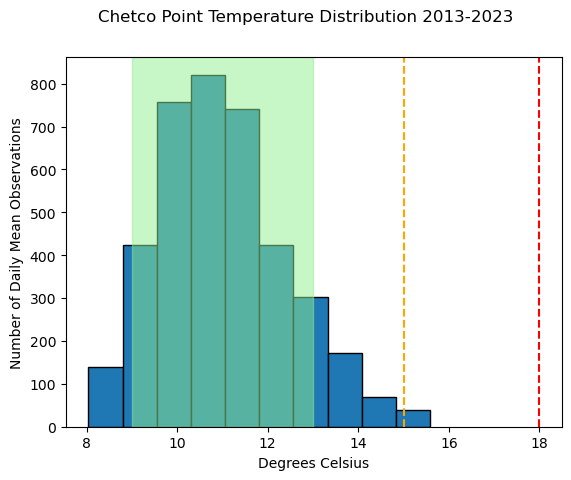

In [6]:
sitecoords = temp_forsites[["lat_rho","lon_rho"]].drop_duplicates()
type(temp_forsites)
for i in [0,1,2,3,4,5,6,7,8,9,10,11,12,13,14]:
    sitedata = temp_forsites.loc[(temp_forsites["lat_rho"] == sitecoords.iloc[i,0]) & (temp_forsites["lon_rho"] == sitecoords.iloc[i,1])].reset_index()
    fig, ax = plt.subplots()
    title = sites.iloc[i,0] + " Temperature Distribution 2013-2023" 
    fig.suptitle(title)
    ax.hist(sitedata.surf_temp, edgecolor = "black")
    plt.axvline(x=15, color='orange', linestyle='--', label='15 deg. C')
    plt.axvline(x=18, color='r', linestyle='--', label='18 deg. C')
    plt.ylabel("Number of Daily Mean Observations")
    plt.xlabel("Degrees Celsius")
    ax.add_patch(Rectangle((9,0), 4,1000 , alpha = 0.5,color='lightgreen'))
    filename = 'C:/Users/sarah/Documents/GitHub/ORKA_StatusReport_FollowupPaper/StatusReport_FollowupPaper_Figures/TempHistograms/' + sites.iloc[i,1]+  '_TempDist_Feb2026.jpg'
    print(filename)
    plt.savefig(filename, dpi = 600)
    plt.show()


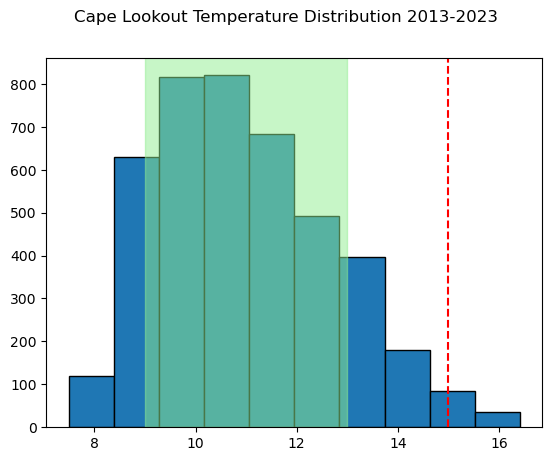

In [61]:
#by site temeprature histograms

#for i in [0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15]:
sitedata = temp_forsites.loc[(temp_forsites["lat_rho"] == sitecoords.iloc[0,0]) & (temp_forsites["lon_rho"] == sitecoords.iloc[0,1])].reset_index()
fig, ax = plt.subplots()
suptitle = 
fig.suptitle("Cape Lookout Temperature Distribution 2013-2023")
ax.hist(sitedata.surf_temp, edgecolor = "black")
plt.axvline(x=15, color='r', linestyle='--', label='15 deg. C')
ax.add_patch(Rectangle((9,0), 4,900 , alpha = 0.5,color='lightgreen'))
plt.show()




In [18]:
#by site, time above 18, 15, 12 and mean temp

def time_above_15(data):
    return len(data.loc[data.surf_temp > 15])/len(data)*100
tempover15 = temp_forsites.groupby("lat_rho").apply(time_above_15).reset_index()
#and then assign to the matrix
tempover15_reordered = tempover15.iloc[::-1].reset_index()
sites["Temp_Over15"] = tempover15_reordered.iloc[:,2]

def time_above_18(data):
    return len(data.loc[data.surf_temp > 18])/len(data)*100
tempover18 = temp_forsites.groupby("lat_rho").apply(time_above_18).reset_index()
#and then assign to the matrix
tempover18_reordered = tempover18.iloc[::-1].reset_index()
sites["Temp_Over18"] = tempover18_reordered.iloc[:,2]

def time_above_12(data):
    return len(data.loc[data.surf_temp > 12])/len(data)*100
tempover12 = temp_forsites.groupby("lat_rho").apply(time_above_12).reset_index()
#and then assign to the matrix
tempover12_reordered = tempover12.iloc[::-1].reset_index()
sites["Temp_Over12"] = tempover12_reordered.iloc[:,2]

def time_9deg_to13deg(data):
    return len(data.loc[(data.surf_temp >= 9) & (data.surf_temp <= 13)])/len(data)*100
temp9to13 = temp_forsites.groupby("lat_rho").apply(time_9deg_to13deg).reset_index()
#and then assign to the matrix
temp9to13_reordered = temp9to13.iloc[::-1].reset_index()
sites["Temp_9to13deg"] = temp9to13_reordered.iloc[:,2]

tempmean = temp_forsites.groupby("lat_rho").surf_temp.mean()
tempmean_reordered = tempmean.iloc[::-1].reset_index()
sites["Temp_Mean"] = tempmean_reordered.iloc[:,1]
sites

temp90 = temp_forsites.groupby("lat_rho").surf_temp.quantile(0.9)
temp90_reordered = temp90.iloc[::-1].reset_index()
sites["Temp_90th"] = temp90_reordered.iloc[:,1]
sites

sites.to_csv("C:/Users/sarah/Documents/GitHub/ORKA_StatusReport_FollowupPaper/StatusReport_FollowupPaper_Figures/SummaryStats_TempDistributions.csv")

C:\Users\sarah\AppData\Local\Temp\ipykernel_48896\1002292634.py:5: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  tempover15 = temp_forsites.groupby("lat_rho").apply(time_above_15).reset_index()
C:\Users\sarah\AppData\Local\Temp\ipykernel_48896\1002292634.py:12: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  tempover18 = temp_forsites.groupby("lat_rho").apply(time_above_18).reset_index()
C:\Users\sarah\AppData\Local\Te

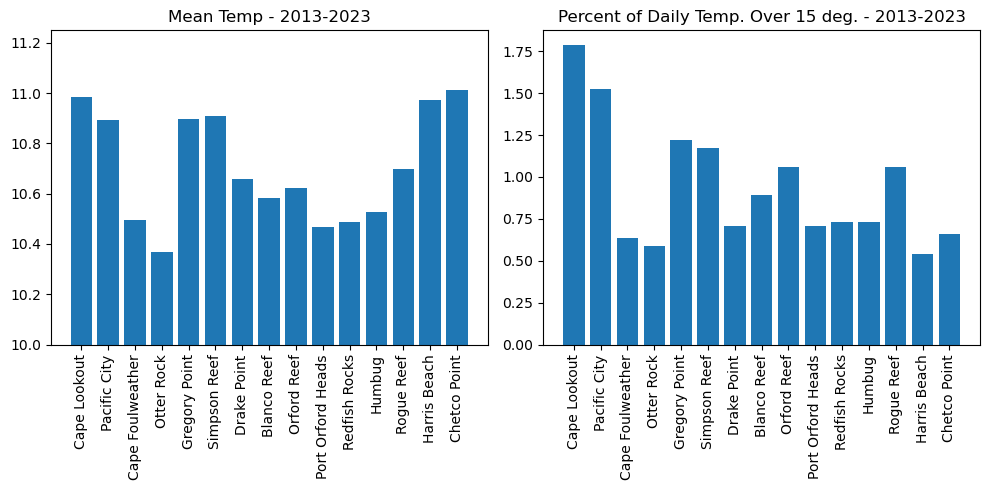

In [48]:
fig, axs = plt.subplots(1,2, figsize = (10,5))
axs[0].bar(sites.Site, sites.Temp_Mean)
axs[0].tick_params("x", rotation=90)
axs[0].set_ylim(10,11.25)
axs[0].set_title("Mean Temp - 2013-2023")
axs[1].bar(sites.Site, sites.Temp_Over15)
axs[1].tick_params("x", rotation=90)
axs[1].set_title("Percent of Daily Temp. Over 15 deg. - 2013-2023")
plt.tight_layout()
plt.show()